# Customer Feedback Intelligence System

## Day 9 — Aspect Identification

**Project Type:** Data Science / Machine Learning / NLP  

**Domain:** Customer Analytics, NLP, Machine Learning

## 1. Objective

The objective of this task is to identify important aspects or
features mentioned by customers in their reviews.

Aspect identification helps understand which product features,
qualities, and service areas customers discuss in their feedback.

In this task, the complete customer feedback dataset will be analyzed
to identify frequently occurring meaningful words. These words will
then be used to define important customer feedback aspects.

The identified aspects will be analyzed further using aspect-level
sentiment analysis in the next stage.

In [6]:
import pandas as pd
import re
from collections import Counter

import nltk
from nltk.corpus import stopwords

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Cleaned Dataset

The cleaned customer feedback dataset created during the previous
tasks is loaded for aspect identification.

The dataset contains product information, ratings, reviews, and
summaries.

In [7]:
cleaned_file_path = r"C:\archive\Customer_Feedback_Cleaned.csv"

df = pd.read_csv(
    cleaned_file_path,
    encoding="utf-8"
)

print("Cleaned dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Cleaned dataset loaded successfully!
Dataset Shape: (310789, 5)
Columns: ['Product_name', 'Price', 'Rate', 'Review', 'Summary']


## 3. Dataset Verification

Before performing aspect identification, the dataset structure
and important text columns are verified.

In [8]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (310789, 5)

Column Names:
['Product_name', 'Price', 'Rate', 'Review', 'Summary']

Data Types:
Product_name      str
Price           int64
Rate            int64
Review            str
Summary           str
dtype: object


## 4. Inspect Customer Feedback

The `Review` and `Summary` columns contain the main customer
feedback text.

A few records are displayed only for inspection. The actual
analysis will be performed on the complete dataset.

In [9]:
display(
    df[["Review", "Summary"]].head(10)
)

,Review,Summary
0,simply awesome,really worth every single penny work like one ...
1,worth money desert cooler live name,bought crompton ozone desert air cooler month ...
2,worth every penny,great packaging seller important point transpo...
3,fabulous,delivery delayed two day except everything qui...
4,nice product,good cooler crompton height cooler ft inch col...
5,super,cant go wrong crompton brand punjab excellent ...
6,terrific purchase,great cooler great price compact great design ...
7,classy product,awesome product making fake comment bought tri...
8,perfect product,air throw goodlow noise best cooling medium sp...
9,cooler ac cooler,day using cooler room buying cooler love stron...


## 5. Combine Review and Summary

Both `Review` and `Summary` contain useful customer feedback.

Therefore, both text fields are combined into a single text column
for complete aspect analysis.

In [10]:
df["Combined_Text"] = (
    df["Review"].fillna("").astype(str)
    + " "
    + df["Summary"].fillna("").astype(str)
)

print("Review and Summary text combined successfully!")

display(
    df[["Review", "Summary", "Combined_Text"]].head(5)
)

Review and Summary text combined successfully!


,Review,Summary,Combined_Text
0,simply awesome,really worth every single penny work like one ...,simply awesome really worth every single penny...
1,worth money desert cooler live name,bought crompton ozone desert air cooler month ...,worth money desert cooler live name bought cro...
2,worth every penny,great packaging seller important point transpo...,worth every penny great packaging seller impor...
3,fabulous,delivery delayed two day except everything qui...,fabulous delivery delayed two day except every...
4,nice product,good cooler crompton height cooler ft inch col...,nice product good cooler crompton height coole...


## 6. Tokenization

Tokenization is the process of breaking customer feedback into
individual words called tokens.

For example:

"The product quality is excellent"

becomes:

["product", "quality", "excellent"]

The complete dataset is tokenized for further analysis.

In [11]:
df["Tokens"] = df["Combined_Text"].apply(
    lambda text: re.findall(
        r'\b[a-zA-Z]+\b',
        text.lower()
    )
)

print("Tokenization completed successfully!")

display(
    df[["Combined_Text", "Tokens"]].head(5)
)

Tokenization completed successfully!


,Combined_Text,Tokens
0,simply awesome really worth every single penny...,"[simply, awesome, really, worth, every, single..."
1,worth money desert cooler live name bought cro...,"[worth, money, desert, cooler, live, name, bou..."
2,worth every penny great packaging seller impor...,"[worth, every, penny, great, packaging, seller..."
3,fabulous delivery delayed two day except every...,"[fabulous, delivery, delayed, two, day, except..."
4,nice product good cooler crompton height coole...,"[nice, product, good, cooler, crompton, height..."


In [12]:
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

print("English stopwords loaded successfully!")
print("Total Stopwords:", len(stop_words))

English stopwords loaded successfully!
Total Stopwords: 198


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 7. Stopword Removal

Stopwords are common words such as "the", "is", "and", "this",
and "was".

These words usually provide less useful information for identifying
customer feedback aspects.

Therefore, stopwords are removed before calculating word frequency.

In [13]:
df["Filtered_Tokens"] = df["Tokens"].apply(
    lambda tokens: [
        word
        for word in tokens
        if word not in stop_words
    ]
)

print("Stopword removal completed successfully!")

display(
    df[["Tokens", "Filtered_Tokens"]].head(5)
)

Stopword removal completed successfully!


,Tokens,Filtered_Tokens
0,"[simply, awesome, really, worth, every, single...","[simply, awesome, really, worth, every, single..."
1,"[worth, money, desert, cooler, live, name, bou...","[worth, money, desert, cooler, live, name, bou..."
2,"[worth, every, penny, great, packaging, seller...","[worth, every, penny, great, packaging, seller..."
3,"[fabulous, delivery, delayed, two, day, except...","[fabulous, delivery, delayed, two, day, except..."
4,"[nice, product, good, cooler, crompton, height...","[nice, product, good, cooler, crompton, height..."


## 8. Identify Common Words from the Full Dataset

The complete customer feedback dataset is analyzed to identify
frequently occurring meaningful words.

These frequently occurring words help us discover potential
customer feedback aspects from the actual dataset instead of
selecting aspect words manually.

The analysis uses all customer reviews and summaries.

In [14]:
word_frequency = Counter()

for tokens in df["Filtered_Tokens"]:
    word_frequency.update(tokens)

top_words = word_frequency.most_common(50)

print("Top 50 Words in the Full Dataset:\n")

for word, count in top_words:
    print(f"{word}: {count}")

Top 50 Words in the Full Dataset:

product: 158651
good: 147724
nice: 70410
quality: 48996
awesome: 33054
best: 27634
money: 26225
sound: 23582
buy: 22673
super: 22399
purchase: 21864
worth: 21591
excellent: 19404
terrific: 18677
great: 17578
wonderful: 16964
bad: 15670
flipkart: 15346
price: 15007
really: 13443
perfect: 12916
recommended: 12858
must: 12579
one: 12540
dont: 11497
bass: 11355
every: 11286
wow: 10837
working: 10712
market: 10319
simply: 10089
highly: 10031
fabulous: 9941
waste: 9883
penny: 9751
brilliant: 9579
classy: 9572
also: 9567
mindblowing: 9469
like: 9323
better: 8796
time: 8258
ok: 8119
value: 7909
worst: 7886
poor: 7838
go: 7724
use: 7663
happy: 7515
delivery: 7511


## 9. Top Frequent Words

The most frequently occurring words are converted into a DataFrame
for easier analysis and interpretation.

In [15]:
top_words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

display(top_words_df)

,Word,Frequency
0,product,158651
1,good,147724
2,nice,70410
3,quality,48996
4,awesome,33054
5,best,27634
6,money,26225
7,sound,23582
8,buy,22673
9,super,22399


## 10. Visualization of Frequent Words

The top frequently occurring words are visualized using a bar chart.

This visualization helps identify words that frequently appear in
customer feedback and may represent important product or service
aspects.

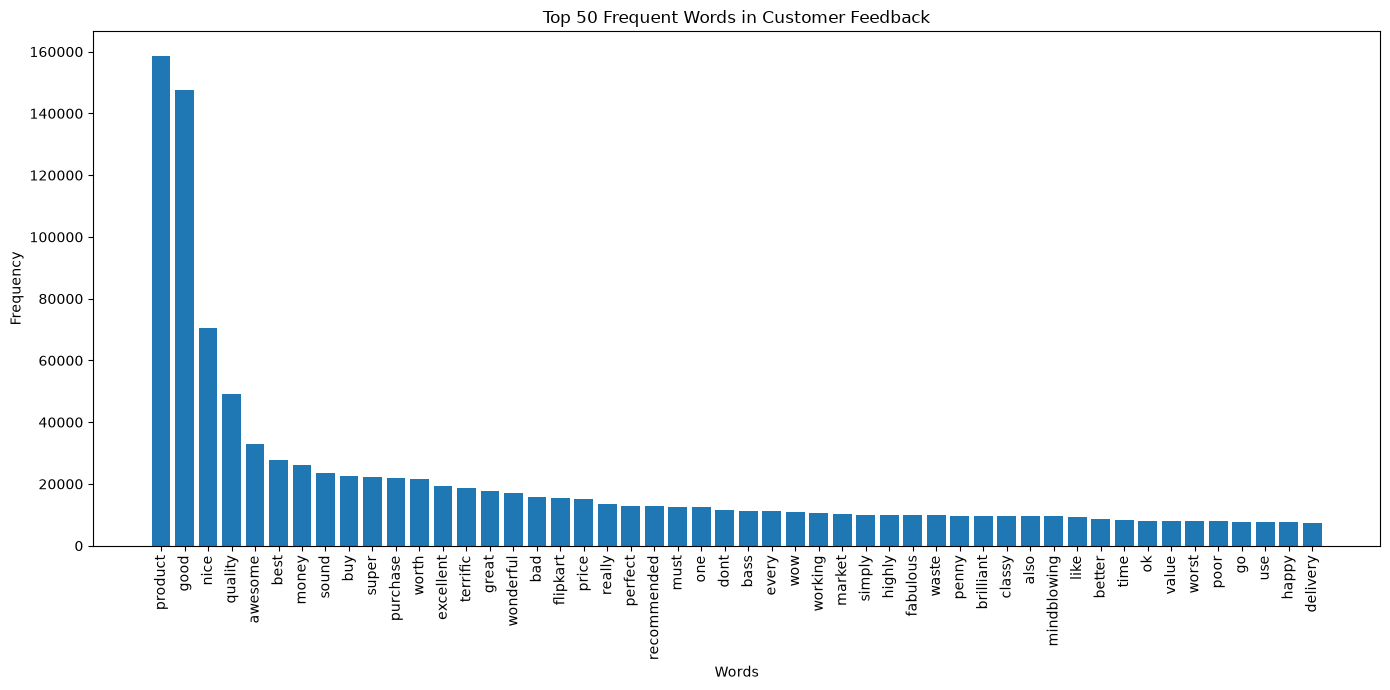

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plt.bar(
    top_words_df["Word"],
    top_words_df["Frequency"]
)

plt.title("Top 50 Frequent Words in Customer Feedback")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(
    rotation=90
)

plt.tight_layout()
plt.show()

## 11. Identify Potential Aspect Candidates

The frequent words identified from the complete dataset are reviewed
to select meaningful words that represent product features,
qualities, or service areas.

Only words that can represent a customer feedback aspect are
considered as aspect candidates.

In [17]:


print("Potential Aspect Candidates:\n")

for word, count in top_words:
    print(f"{word} : {count}")

Potential Aspect Candidates:

product : 158651
good : 147724
nice : 70410
quality : 48996
awesome : 33054
best : 27634
money : 26225
sound : 23582
buy : 22673
super : 22399
purchase : 21864
worth : 21591
excellent : 19404
terrific : 18677
great : 17578
wonderful : 16964
bad : 15670
flipkart : 15346
price : 15007
really : 13443
perfect : 12916
recommended : 12858
must : 12579
one : 12540
dont : 11497
bass : 11355
every : 11286
wow : 10837
working : 10712
market : 10319
simply : 10089
highly : 10031
fabulous : 9941
waste : 9883
penny : 9751
brilliant : 9579
classy : 9572
also : 9567
mindblowing : 9469
like : 9323
better : 8796
time : 8258
ok : 8119
value : 7909
worst : 7886
poor : 7838
go : 7724
use : 7663
happy : 7515
delivery : 7511


## 12. Create Final Aspect Dictionary

Based on the frequent words identified from the complete customer
feedback dataset, meaningful product and service-related words were
selected as aspect candidates.

Words such as `quality`, `price`, `sound`, `bass`, `working`, and
`delivery` represent specific product features or service areas.

Words such as `good`, `nice`, `excellent`, `bad`, and `poor` were not
selected as aspects because they represent customer opinions or
sentiment rather than specific features.

Related words such as `money` and `value` were grouped under the
`price` aspect because they are related to price and value perception.

A final aspect dictionary was created using these meaningful
dataset-based aspect candidates.


In [18]:
aspect_dictionary = {
    "quality": ["quality"],
    "price": ["price", "money", "value"],
    "sound": ["sound"],
    "bass": ["bass"],
    "working": ["working"],
    "delivery": ["delivery"]
}

print("Final Aspect Dictionary created successfully!")

for aspect, keywords in aspect_dictionary.items():
    print(f"{aspect}: {keywords}")

Final Aspect Dictionary created successfully!
quality: ['quality']
price: ['price', 'money', 'value']
sound: ['sound']
bass: ['bass']
working: ['working']
delivery: ['delivery']


## 13. Aspect Detection

The final aspect dictionary is used to identify the aspects mentioned
in each customer feedback record.

Each review is checked against the aspect keywords. If one or more
aspect keywords are found in a review, the corresponding aspect is
identified.

The aspect detection is performed on the complete customer feedback
dataset.


In [19]:
def detect_aspects(tokens):
    detected_aspects = []

    for aspect, keywords in aspect_dictionary.items():
        if any(keyword in tokens for keyword in keywords):
            detected_aspects.append(aspect)

    return detected_aspects


df["Detected_Aspects"] = df["Filtered_Tokens"].apply(
    detect_aspects
)

print("Aspect detection completed successfully!")

display(
    df[
        ["Review", "Summary", "Detected_Aspects"]
    ].head(10)
)

Aspect detection completed successfully!


,Review,Summary,Detected_Aspects
0,simply awesome,really worth every single penny work like one ...,[]
1,worth money desert cooler live name,bought crompton ozone desert air cooler month ...,"[quality, price]"
2,worth every penny,great packaging seller important point transpo...,[price]
3,fabulous,delivery delayed two day except everything qui...,[delivery]
4,nice product,good cooler crompton height cooler ft inch col...,[]
5,super,cant go wrong crompton brand punjab excellent ...,[quality]
6,terrific purchase,great cooler great price compact great design ...,"[price, delivery]"
7,classy product,awesome product making fake comment bought tri...,[]
8,perfect product,air throw goodlow noise best cooling medium sp...,[]
9,cooler ac cooler,day using cooler room buying cooler love stron...,[]


## 14. Aspect Frequency Analysis

The frequency of each identified aspect is calculated across the
complete customer feedback dataset.

This analysis helps determine which product features or service areas
are most frequently mentioned by customers.

The frequency count is based on the complete dataset and not only
the displayed sample records.


In [20]:
aspect_frequency = {}

for aspect in aspect_dictionary.keys():

    count = df["Detected_Aspects"].apply(
        lambda aspects: aspect in aspects
    ).sum()

    aspect_frequency[aspect] = count

print("Aspect Frequency:\n")

for aspect, count in aspect_frequency.items():
    print(f"{aspect}: {count} reviews")

Aspect Frequency:

quality: 45133 reviews
price: 39226 reviews
sound: 20807 reviews
bass: 10061 reviews
working: 10069 reviews
delivery: 6895 reviews


## 15. Aspect Frequency Results

The calculated aspect frequencies are converted into a DataFrame
for easier comparison and interpretation.

The results are sorted in descending order so that the most
frequently mentioned aspects appear first.


In [21]:
aspect_frequency_df = pd.DataFrame(
    list(aspect_frequency.items()),
    columns=["Aspect", "Frequency"]
)

aspect_frequency_df = aspect_frequency_df.sort_values(
    by="Frequency",
    ascending=False
).reset_index(drop=True)

display(aspect_frequency_df)

,Aspect,Frequency
0,quality,45133
1,price,39226
2,sound,20807
3,working,10069
4,bass,10061
5,delivery,6895


## 16. Aspect Frequency Visualization

A bar chart is used to visualize the frequency of the identified
customer feedback aspects.

The visualization helps compare how frequently different product
features and service areas are mentioned by customers.


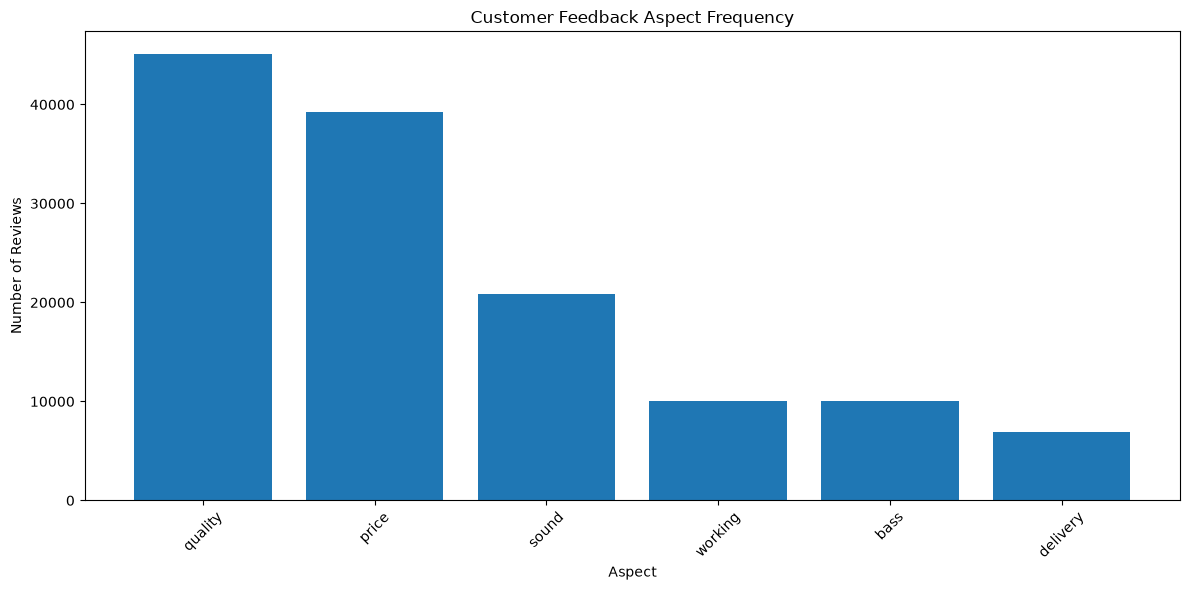

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    aspect_frequency_df["Aspect"],
    aspect_frequency_df["Frequency"]
)

plt.title("Customer Feedback Aspect Frequency")
plt.xlabel("Aspect")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 17. Identify Important Customer Feedback Aspects

The aspect frequency results are analyzed to identify the most
frequently discussed customer feedback aspects.

Aspects with higher frequency indicate product features or service
areas that are commonly mentioned by customers.

These important aspects will be used for further aspect-level
sentiment analysis.


In [23]:
print("Important Customer Feedback Aspects:\n")

for _, row in aspect_frequency_df.iterrows():
    print(
        f"{row['Aspect']}: "
        f"{row['Frequency']} reviews"
    )

Important Customer Feedback Aspects:

quality: 45133 reviews
price: 39226 reviews
sound: 20807 reviews
working: 10069 reviews
bass: 10061 reviews
delivery: 6895 reviews


## 18. Final Result

The complete customer feedback dataset was analyzed to identify
meaningful and frequently discussed customer feedback aspects.

Frequent words were first identified from the full dataset.
Meaningful product and service-related words were then selected
as aspect candidates.

Using the final aspect dictionary, the aspects were detected across
the complete dataset and their frequencies were calculated.

The analysis identified the following important aspects:

* Quality — 45,133 reviews
* Price — 39,226 reviews
* Sound — 20,807 reviews
* Working — 10,069 reviews
* Bass — 10,061 reviews
* Delivery — 6,895 reviews

These identified aspects will be used in Day 10 for aspect-level
sentimen


## 19. Conclusion

In this task, important customer feedback aspects were identified
from the complete customer feedback dataset.

The Review and Summary text fields were combined, tokenized, and
processed by removing common stopwords. Frequent words were then
analyzed to identify meaningful product features and service-related
aspects.

The selected aspects were detected across the complete dataset, and
their frequencies were calculated and visualized using a bar chart.

Quality, Price, and Sound were among the most frequently mentioned
aspects in the analyzed customer feedback.

The identified aspects provide the foundation for the next stage,
Day 10 — Aspect-Level Sentiment Analysis.
